# 📈 Análise de Câmbio: o Real frente a outras moedas (2015–2026)

Neste notebook eu analiso as cotações coletadas pelo `coleta.py` (API do Banco Central) para responder quatro perguntas:

1. Qual moeda mais se valorizou frente ao Real desde 2015?
2. Qual moeda foi a mais volátil?
3. Como o Real reagiu à pandemia de 2020?
4. Existe padrão sazonal no dólar?

## 1. Carregando e conhecendo os dados

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

df = pd.read_csv("data/cotacoes.csv", index_col="data", parse_dates=True)
df.head()

,USD,EUR,GBP,JPY
data,,,,
2015-01-02,2.6929,3.2379,4.1476,0.02232
2015-01-05,2.7107,3.2349,4.1295,0.02269
2015-01-06,2.7023,3.2182,4.1007,0.02274
2015-01-07,2.6807,3.1683,4.0436,0.02243
2015-01-08,2.6919,3.1764,4.0618,0.02252


In [14]:
print(f"Período: {df.index.min():%d/%m/%Y} a {df.index.max():%d/%m/%Y}")
print(f"Total de dias com cotação: {len(df)}\n")

resumo = pd.DataFrame({
    "cotações": df.count(),
    "faltando": df.isna().sum(),
    "primeira": df.apply(lambda s: s.first_valid_index()).dt.strftime("%d/%m/%Y"),
    "última": df.apply(lambda s: s.last_valid_index()).dt.strftime("%d/%m/%Y"),
})
resumo

Período: 02/01/2015 a 30/10/2026
Total de dias com cotação: 2968



,cotações,faltando,primeira,última
USD,2968,0,02/01/2015,30/10/2026
EUR,2966,2,02/01/2015,30/10/2026
GBP,2966,2,02/01/2015,30/10/2026
JPY,2965,3,02/01/2015,30/10/2026


**Tratamento dos dados:** a API só publica cotações em dias úteis, então não há fins de semana na tabela.
Os poucos valores faltando são feriados ou dias em que uma moeda não teve cotação publicada.
Cada moeda é analisada usando apenas os dias em que tem dados, sem inventar valores.

## 2. Visão geral: evolução das cotações

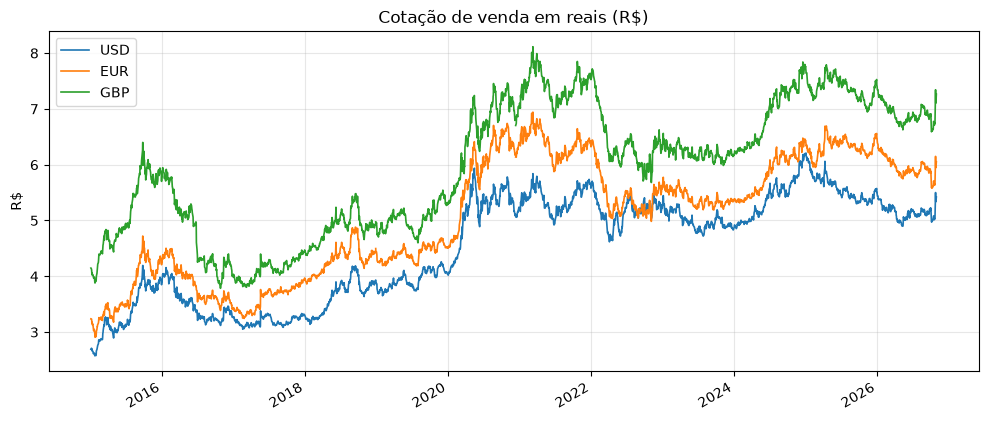

In [15]:
moedas_principais = ["USD", "EUR", "GBP"]

fig, ax = plt.subplots()
df[moedas_principais].plot(ax=ax, linewidth=1.2)
ax.set_title("Cotação de venda em reais (R$)")
ax.set_xlabel("")
ax.set_ylabel("R$")
plt.show()

Como as moedas têm valores muito diferentes (o iene vale centavos, a libra mais de R$ 7), comparar os preços direto engana.
A solução é colocar todas na **base 100**: o primeiro dia de 2015 vira 100 e o resto mostra a variação a partir dali.

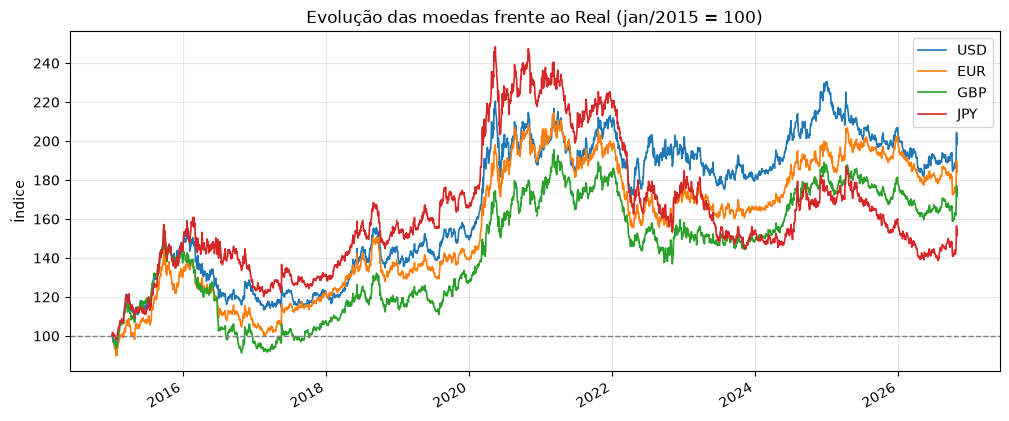

In [16]:
base100 = df.apply(lambda s: s / s.dropna().iloc[0] * 100)

fig, ax = plt.subplots()
base100[["USD", "EUR", "GBP", "JPY"]].plot(ax=ax, linewidth=1.2)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)
ax.set_title("Evolução das moedas frente ao Real (jan/2015 = 100)")
ax.set_xlabel("")
ax.set_ylabel("Índice")
plt.show()

## 3. Pergunta 1: qual moeda mais se valorizou frente ao Real?

Todas as moedas analisadas ficaram mais caras em reais desde 2015, ou seja, o Real perdeu valor frente a todas elas. O dólar foi o destaque: dobrou de preço (+101%), passando de R$ 2,69 para cerca de R$ 5,42. Em seguida vieram o euro (+87%), a libra (+75%) e o iene (+54%).

In [17]:
def variacao_total(s):
    s = s.dropna()
    return (s.iloc[-1] / s.iloc[0] - 1) * 100

valorizacao = df.apply(variacao_total).sort_values(ascending=False).round(1)
valorizacao.to_frame("variação desde 2015 (%)")

,variação desde 2015 (%)
USD,101.3
EUR,86.9
GBP,75.1
JPY,54.3


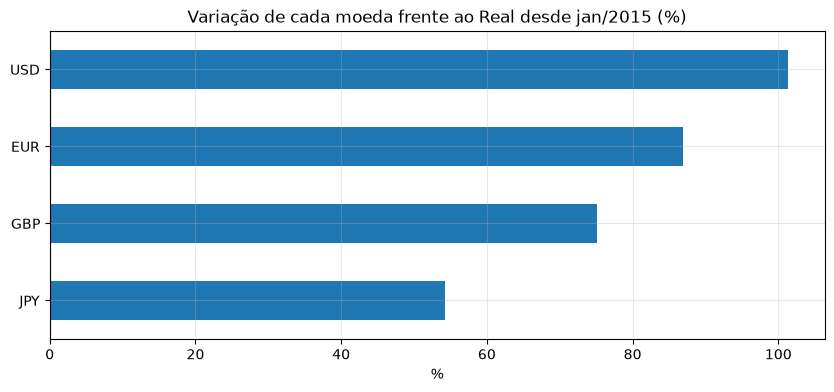

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
cores = ["tab:red" if v < 0 else "tab:blue" for v in valorizacao]
valorizacao.plot.barh(ax=ax, color=cores)
ax.invert_yaxis()
ax.set_title("Variação de cada moeda frente ao Real desde jan/2015 (%)")
ax.set_xlabel("%")
plt.show()

**Como ler:** valor positivo significa que a moeda ficou mais cara em reais (o Real perdeu valor frente a ela);
valor negativo significa que ficou mais barata (o Real ganhou).

📝 *Escreva aqui a sua conclusão depois de rodar.*

## 4. Pergunta 2: qual moeda foi a mais volátil?

As quatro moedas tiveram volatilidade parecida, em torno de 15% ao ano, com o iene levemente acima das demais. O mais interessante é a variação ao longo do tempo: os anos mais instáveis foram 2015, marcado pela crise política e econômica no Brasil, e 2020, por causa da pandemia. Os períodos mais calmos foram 2019 e 2025.

Volatilidade mede o quanto a cotação "chacoalha" de um dia para o outro.
Calculo a variação percentual diária de cada moeda e depois o desvio padrão dessas variações, anualizado (multiplicado pela raiz de 252, o número aproximado de dias úteis no ano).

In [19]:
retornos = df.pct_change(fill_method=None)

volatilidade = (retornos.std() * (252 ** 0.5) * 100).sort_values(ascending=False).round(1)
volatilidade.to_frame("volatilidade anual (%)")

,volatilidade anual (%)
JPY,16.7
GBP,15.2
EUR,14.8
USD,14.8


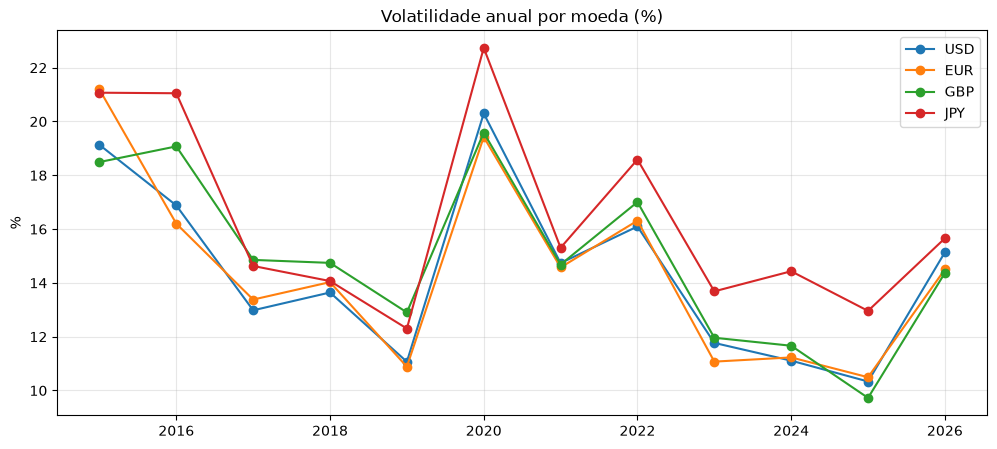

In [20]:
vol_anual = retornos.groupby(retornos.index.year).std() * (252 ** 0.5) * 100

fig, ax = plt.subplots()
vol_anual[["USD", "EUR", "GBP", "JPY"]].plot(ax=ax, marker="o")
ax.set_title("Volatilidade anual por moeda (%)")
ax.set_xlabel("")
ax.set_ylabel("%")
plt.show()

📝 *Escreva aqui a sua conclusão: qual moeda foi mais volátil e em quais anos a volatilidade subiu.*

## 5. Pergunta 3: como o Real reagiu à pandemia de 2020?


A pandemia provocou a maior disparada do período. O dólar saiu de R$ 4,50 no fim de fevereiro de 2020 para R$ 5,94 em 14 de maio, uma alta de 32% em menos de três meses. Momentos de crise global costumam levar investidores a buscar moedas consideradas mais seguras, o que pressiona moedas de países emergentes como o Real.

In [21]:
usd = df["USD"].dropna()
periodo = usd["2019-10-01":"2021-06-30"]

antes = usd[:"2020-02-28"].iloc[-1]
pico_data = usd["2020"].idxmax()
pico = usd["2020"].max()

print(f"Dólar no fim de fev/2020: R$ {antes:.2f}")
print(f"Pico em 2020: R$ {pico:.2f} em {pico_data:%d/%m/%Y}")
print(f"Alta até o pico: {(pico / antes - 1) * 100:.1f}%")

Dólar no fim de fev/2020: R$ 4.50
Pico em 2020: R$ 5.94 em 14/05/2020
Alta até o pico: 32.0%


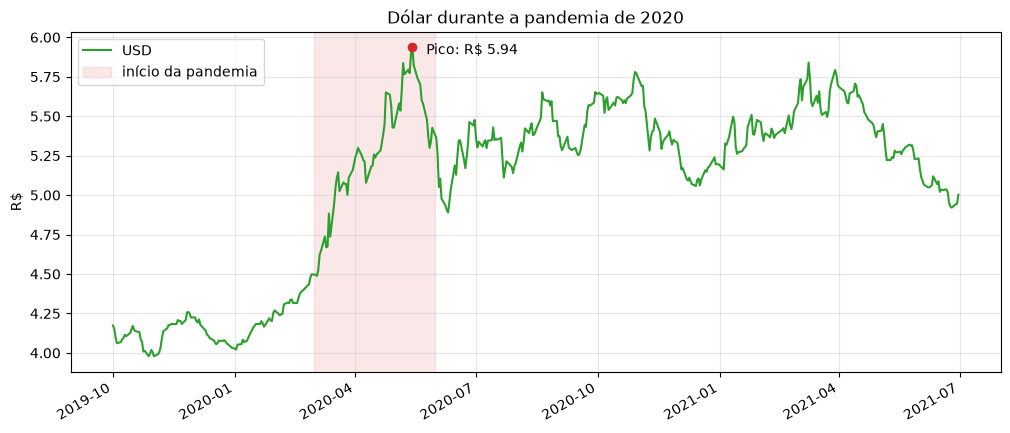

In [22]:
fig, ax = plt.subplots()
periodo.plot(ax=ax, color="tab:green", linewidth=1.5)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color="tab:red", alpha=0.1,
           label="início da pandemia")
ax.scatter(pico_data, pico, color="tab:red", zorder=5)
ax.annotate(f"Pico: R$ {pico:.2f}", (pico_data, pico), xytext=(10, -5), textcoords="offset points")
ax.set_title("Dólar durante a pandemia de 2020")
ax.set_xlabel("")
ax.set_ylabel("R$")
ax.legend()
plt.show()

📝 *Escreva aqui a sua conclusão sobre o impacto da pandemia no câmbio.*

## 6. Pergunta 4: existe padrão sazonal no dólar?


À primeira vista, agosto parece o mês em que o dólar mais sobe (+3% em média). Porém, essa média é puxada por três anos atípicos (2015, 2018 e 2019, com altas próximas de 10%); nos demais anos, agosto foi praticamente neutro. Com apenas 11 anos de dados, não é possível afirmar que existe um padrão sazonal confiável.

Para cada mês, calculo a variação do dólar entre o fim do mês anterior e o fim daquele mês, e depois a média por mês do ano.
Assim dá para ver se algum mês costuma ter dólar subindo ou caindo.

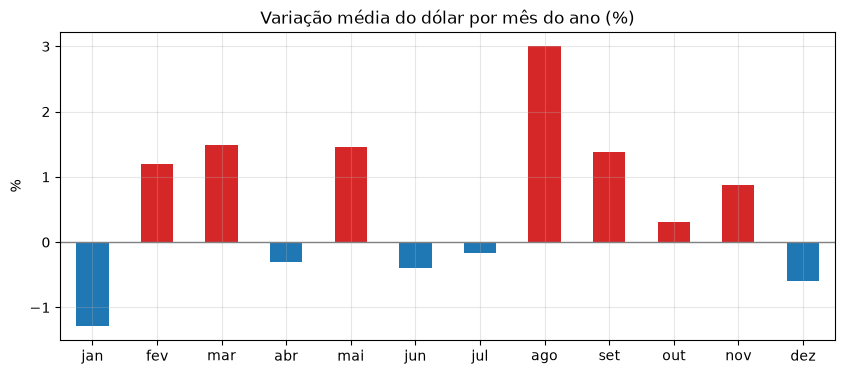

,variação média (%)
jan,-1.28
fev,1.20
mar,1.49
abr,-0.30
mai,1.45
jun,-0.40
jul,-0.17
ago,3.01
set,1.38
out,0.32


In [23]:
usd_mensal = df["USD"].dropna().resample("ME").last()
var_mensal = usd_mensal.pct_change().dropna() * 100

meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
sazonal = var_mensal.groupby(var_mensal.index.month).mean()
sazonal.index = [meses[m - 1] for m in sazonal.index]

fig, ax = plt.subplots(figsize=(10, 4))
cores = ["tab:red" if v > 0 else "tab:blue" for v in sazonal]
sazonal.plot.bar(ax=ax, color=cores)
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Variação média do dólar por mês do ano (%)")
ax.set_xlabel("")
ax.set_ylabel("%")
plt.xticks(rotation=0)
plt.show()

sazonal.round(2).to_frame("variação média (%)")

**Cuidado na interpretação:** são cerca de 11 anos de dados, ou seja, só umas 11 observações por mês.
Uma média puxada por um único ano atípico (como 2020) pode parecer um padrão sem ser.

📝 *Escreva aqui a sua conclusão.*

## 7. Conclusões


Entre 2015 e 2026, o Real perdeu valor frente a todas as moedas analisadas, com o dólar dobrando de preço. A instabilidade do câmbio se concentrou em momentos de crise, como 2015 e a pandemia de 2020, quando o dólar subiu 32% em menos de três meses. Já a ideia de que existe um “mês certo” para comprar dólar não se sustenta: a aparente sazonalidade é explicada por poucos anos atípicos. Durante o projeto, a validação dos dados também mostrou que uma das séries inicialmente usadas não correspondia ao peso argentino, e ela foi retirada da análise.